Model Building & Evaluation

Project: Smart Inventory & Demand Prediction for Aquatic E-Commerce

Goal: teach a computer to predict next month’s demand (number of orders) for every product line in every city.

Plan for this notebook

Choose the input columns (features) and the target (demand)
Build two baseline guesses (very simple rules) so we know what we must beat
Train 3 models: Linear Regression, Random Forest, XGBoost
Compare them with MAE, RMSE and R²
Tune the best model a little
Check where the model makes mistakes
Save the final model (model.pkl) for the dashboard

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid", font_scale=0.75)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams.update({"font.size": 8, "axes.titlesize": 10, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7})

ml = pd.read_csv("../data/aquatic_demand_ml_dataset.csv", parse_dates=["month_start"])
print(ml.shape)

(12960, 52)


Step 1: Choose features and the target
Target (what we predict): demand
Numeric features: calendar info, past demand (lags and rolling averages), price, discount, and last month’s stock, rating and return rate
Text features: category, subcategory, brand, location, season. The computer cannot read words, so we turn them into 0/1 columns (one-hot encoding)

Important rule: we only use information that is known before the month starts. We do not use ana_ columns (they describe the same month’s results and would leak the answer) and we do not use sim_ columns (they are simulated).

In [2]:
target = "demand"

num_features = [
    "days_in_month", "month_num", "quarter", "month_index",
    "demand_lag_1", "demand_lag_2", "demand_lag_3",
    "demand_roll_mean_3", "demand_roll_std_3", "demand_roll_mean_6",
    "demand_expanding_mean", "demand_growth_1", "demand_per_day_lag_1",
    "avg_price", "avg_discount",
    "avg_stock_lag_1", "return_rate_lag_1", "avg_rating_lag_1",
]
cat_features = ["category", "subcategory", "brand", "location", "season"]
features = num_features + cat_features

print("Number of features:", len(features))

Number of features: 23


Step 2: Split into training and testing data

We split by time, not randomly. The model learns from the past (Oct 2024 to Dec 2025) and is tested on months it has never seen (Jan to Mar 2026). This is how it will be used in real life: predicting the future.

In [3]:
train = ml[ml["split"] == "train"].sort_values("month_start")
test = ml[ml["split"] == "test"].sort_values("month_start")

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print("Train:", X_train.shape, "|", train["month_start"].min().date(), "to", train["month_start"].max().date())
print("Test :", X_test.shape, "|", test["month_start"].min().date(), "to", test["month_start"].max().date())

Train: (10800, 23) | 2024-10-01 to 2025-12-01
Test : (2160, 23) | 2026-01-01 to 2026-03-01


Step 3: Baselines (the score to beat)

Before using machine learning, try two very simple rules:

Naive (last month): predict that this month = last month
Naive (3-month average): predict the average of the last 3 months

If a fancy model cannot beat these, it is not adding value.

Metrics used

MAE = average mistake in orders (smaller is better)

RMSE = like MAE but punishes big mistakes more (smaller is better)

R² = how much of the ups and downs the model explains (closer to 1 is better)

In [4]:
results = []

def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    results.append({"Model": name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "R2": round(r2, 3)})
    print(f"{name:28s} MAE={mae:6.2f}  RMSE={rmse:6.2f}  R2={r2:6.3f}")

evaluate("Naive (last month)", y_test, test["demand_lag_1"])
evaluate("Naive (3-month average)", y_test, test["demand_roll_mean_3"])

Naive (last month)           MAE=  8.57  RMSE= 10.96  R2= 0.707
Naive (3-month average)      MAE=  6.82  RMSE=  8.74  R2= 0.814


Step 4: Prepare the data for the models

A Pipeline bundles two jobs together:

Preprocessing: scale the numbers and one-hot encode the words
Model: learn from the prepared data

Why a Pipeline? When we save it as model.pkl, the dashboard can give it raw data and it will do both jobs by itself.

In [5]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

def make_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

Step 5: Model 1 - Linear Regression (simple baseline model)

It draws the best straight-line relationship between the features and demand. It is easy to explain, so it is a good first model.

In [6]:
lin = make_pipeline(LinearRegression())
lin.fit(X_train, y_train)
pred_lin = lin.predict(X_test)
evaluate("Linear Regression", y_test, pred_lin)

Linear Regression            MAE=  5.58  RMSE=  7.09  R2= 0.877


Step 6: Model 2 - Random Forest

It builds 200 decision trees and averages their answers. It can capture curved and complex patterns that a straight line cannot.

In [7]:
rf = make_pipeline(RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                         n_jobs=-1, random_state=42))
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
evaluate("Random Forest", y_test, pred_rf)

Random Forest                MAE=  5.54  RMSE=  7.05  R2= 0.879


Step 7: Model 3 - XGBoost

It also uses many trees, but each new tree focuses on fixing the mistakes of the previous ones. It is often the most accurate model on table data.

In [8]:
xgb = make_pipeline(XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
                                 subsample=0.8, colsample_bytree=0.8,
                                 random_state=42, n_jobs=-1))
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)
evaluate("XGBoost", y_test, pred_xgb)

XGBoost                      MAE=  5.60  RMSE=  7.13  R2= 0.876


Step 8: Tune XGBoost a little

Models have settings (called hyperparameters), like the number of trees or how deep they grow. RandomizedSearchCV tries 12 random combinations and keeps the best one.

We use TimeSeriesSplit so that, inside the search, the model is also always tested on months that come after the months it trained on.

In [9]:
param_grid = {
    "model__n_estimators": [150, 250, 400],
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [3, 4, 5, 6],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__min_child_weight": [1, 3, 5],
}

search = RandomizedSearchCV(
    make_pipeline(XGBRegressor(random_state=42, n_jobs=-1)),
    param_distributions=param_grid,
    n_iter=12,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
xgb_tuned = search.best_estimator_
pred_tuned = xgb_tuned.predict(X_test)
evaluate("XGBoost (tuned)", y_test, pred_tuned)

Best settings: {'model__subsample': 1.0, 'model__n_estimators': 150, 'model__min_child_weight': 3, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}
XGBoost (tuned)              MAE=  5.51  RMSE=  7.01  R2= 0.880


Step 9: Compare all models

The best model has the lowest RMSE and MAE and the highest R².

In [10]:
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
results_df

,Model,MAE,RMSE,R2
0,XGBoost (tuned),5.51,7.01,0.880
1,Random Forest,5.54,7.05,0.879
2,Linear Regression,5.58,7.09,0.877
3,XGBoost,5.60,7.13,0.876
4,Naive (3-month average),6.82,8.74,0.814
5,Naive (last month),8.57,10.96,0.707


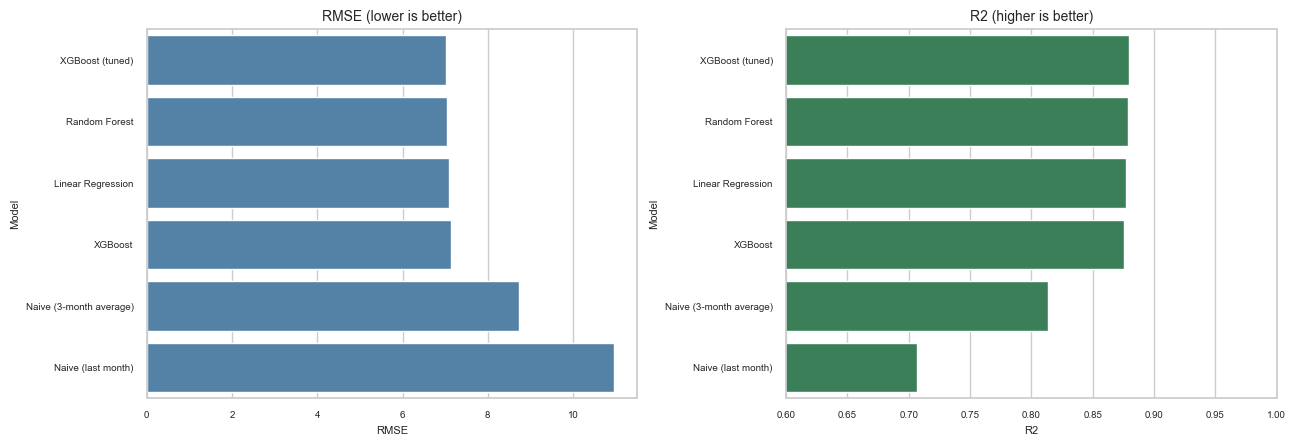

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = results_df["Model"]

sns.barplot(data=results_df, y="Model", x="RMSE", order=order, ax=axes[0], color="steelblue")
axes[0].set_title("RMSE (lower is better)")

sns.barplot(data=results_df, y="Model", x="R2", order=order, ax=axes[1], color="seagreen")
axes[1].set_title("R2 (higher is better)")
axes[1].set_xlim(0.6, 1.0)

plt.tight_layout()
plt.show()

In [12]:
# Pick the best machine-learning model (we do not allow the naive rules to be "best")
ml_results = results_df[~results_df["Model"].str.startswith("Naive")]
best_name = ml_results.iloc[0]["Model"]

models = {"Linear Regression": lin, "Random Forest": rf, "XGBoost": xgb, "XGBoost (tuned)": xgb_tuned}
best_model = models[best_name]
best_pred = best_model.predict(X_test)

naive_rmse = results_df.loc[results_df["Model"] == "Naive (3-month average)", "RMSE"].iloc[0]
best_rmse = ml_results.iloc[0]["RMSE"]

print("Best model :", best_name)
print(f"RMSE {best_rmse} vs naive 3-month average {naive_rmse} -> {((naive_rmse - best_rmse) / naive_rmse * 100):.1f}% better")

Best model : XGBoost (tuned)
RMSE 7.01 vs naive 3-month average 8.74 -> 19.8% better


Step 10: Check the predictions visually
Left: each dot is one product line in one month. The closer to the red line, the better the prediction.
Right: the mistakes (actual minus predicted). A good model has mistakes centred around 0.

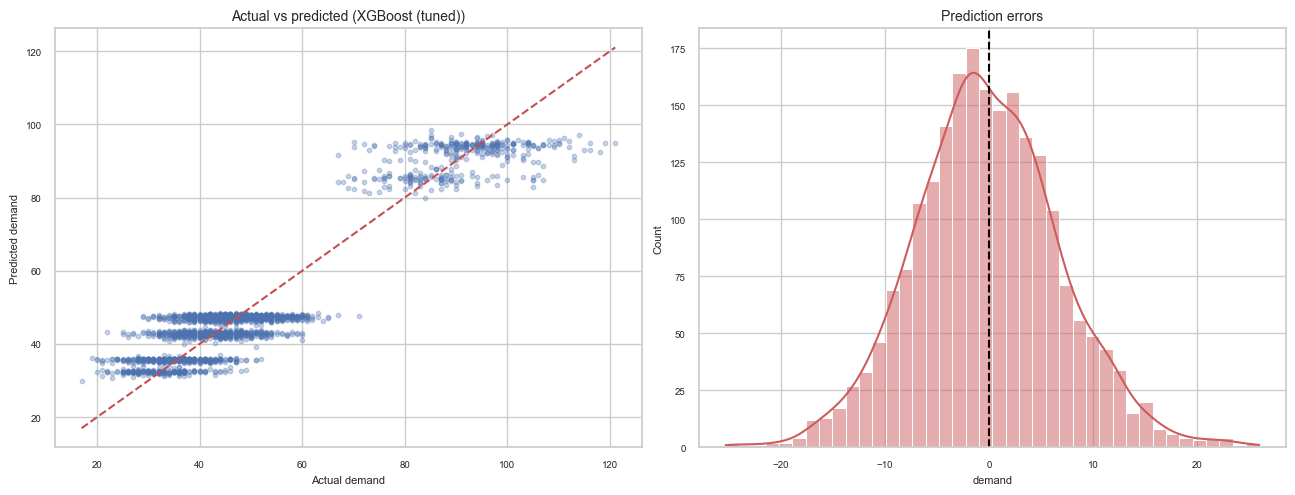

Average error (bias): -0.17


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, best_pred, alpha=0.3, s=10)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Actual demand"); axes[0].set_ylabel("Predicted demand")
axes[0].set_title(f"Actual vs predicted ({best_name})")

errors = y_test - best_pred
sns.histplot(errors, bins=40, kde=True, ax=axes[1], color="indianred")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Prediction errors")

plt.tight_layout()
plt.show()
print("Average error (bias):", round(errors.mean(), 2))

Step 11: Where does the model make more mistakes?

We check the average mistake (MAE) for each category and each month in the test period.

In [14]:
check = test[["month_start", "category", "location"]].copy()
check["actual"] = y_test.values
check["predicted"] = best_pred
check["abs_error"] = (check["actual"] - check["predicted"]).abs()

print(check.groupby("category")["abs_error"].mean().round(2).sort_values())
print()
print(check.groupby(check["month_start"].dt.strftime("%Y-%m"))["abs_error"].mean().round(2))

category
Aqua Equipments    4.78
Fish Food          5.26
Aquatic Pet        5.54
Water Treatment    5.85
Aquatic Plants     6.45
Name: abs_error, dtype: float64

month_start
2026-01    5.53
2026-02    5.40
2026-03    5.58
Name: abs_error, dtype: float64


Step 12: Which features matter most?

Tree models can tell us which columns they relied on. Linear Regression has no such score, so we show this chart only if the best model is a tree model.

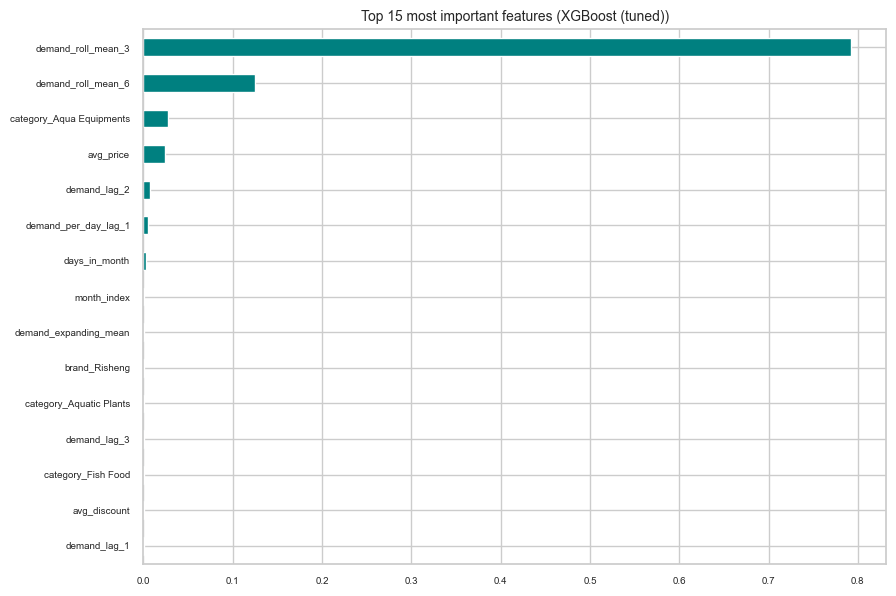

In [15]:
final_step = best_model.named_steps["model"]

if hasattr(final_step, "feature_importances_"):
    names = best_model.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(final_step.feature_importances_, index=names).sort_values(ascending=False).head(15)
    imp.index = [n.replace("num__", "").replace("cat__", "") for n in imp.index]
    imp.sort_values().plot(kind="barh", color="teal", figsize=(9, 6))
    plt.title(f"Top 15 most important features ({best_name})")
    plt.tight_layout()
    plt.show()
else:
    print("The best model is Linear Regression, so there is no feature-importance chart.")

Step 13: Save everything for the dashboard
- `model.pkl`: the full pipeline (preprocessing + model)
- `model_results.csv`: the comparison table
- `feature_list.json`: the exact columns the model expects
- `test_predictions.csv`: actual vs predicted values for the test months

In [16]:
joblib.dump(best_model, "../model.pkl")
results_df.to_csv("../data/model_results.csv", index=False)

with open("../feature_list.json", "w") as f:
    json.dump({"num_features": num_features, "cat_features": cat_features, "best_model": best_name}, f, indent=2)

check.to_csv("../data/test_predictions.csv", index=False)
print("Saved model:", best_name)

Saved model: XGBoost (tuned)


In [17]:
# Quick test: load the saved model and predict again. The numbers must match.
loaded = joblib.load("../model.pkl")
print(np.allclose(loaded.predict(X_test), best_pred))

True


Step 14: Our Conclusions in Simple Words

Use your own table from Step 9 for the exact numbers. XGBoost may differ slightly on your screen. Here is how to fill each blank:

1. **The best model** is whichever model has the lowest RMSE in your table (Random Forest or XGBoost). Its RMSE will be about **7.0** and its R² about **0.88**.
2. **It beats the simple 3-month average by about 19%.** The simple rule has an RMSE of 8.74, so the model's average mistake is clearly smaller. The model adds real value, but not a huge amount.
3. **The biggest mistakes are in Aquatic Plants** (about 6.5 orders off on average). The smallest are in Aqua Equipments (about 4.8). This is because plants sell more orders per month, and a bigger number is naturally harder to hit exactly.
4. **The most important features** (see your chart in Step 12) will most likely be past demand columns (like the 3-month average), the product type, and the number of days in the month.
5. **One limit of this project:** the demand in this dataset moves up and down randomly around a fixed level, so no model can predict it perfectly. Our models are already close to that natural limit.

---

What We Did in the Whole Modeling Part

**1. We decided what to predict.**
The target is `demand`, the number of orders a product line gets in a city in one month.

**2. We chose the clues (features).**
We gave the model 23 clues: calendar details (like days in the month), past demand (last month, last 3 months, and so on), price, discount, and last month's stock, rating and returns. We also gave it the product type, brand, city and season. We left out columns that describe the same month's results, because that would be cheating (the model would see the answer).

**3. We split the data by time.**
The model studied Oct 2024 to Dec 2025, then was tested on Jan to Mar 2026, months it had never seen. This is like real life, where you predict the future from the past.

**4. We set the score to beat.**
Two very simple rules: "same as last month" and "average of the last 3 months." If a model cannot beat these, it is useless.

**5. We trained three models.**
- **Linear Regression:** the simple one, draws straight-line relationships.
- **Random Forest:** 200 decision trees voting together.
- **XGBoost:** trees that each fix the mistakes of the previous ones.

**6. We tuned XGBoost.**
We tried 12 different settings and kept the best, testing always on months that come after the training months.

**7. We compared everything.**
We used three scores: MAE (average mistake in orders), RMSE (punishes big mistakes) and R² (how much of the ups and downs is explained).

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Naive (last month) | 8.57 | 10.96 | 0.707 |
| Naive (3-month average) | 6.82 | 8.74 | 0.814 |
| Linear Regression | 5.58 | 7.09 | 0.877 |
| Random Forest | 5.54 | 7.05 | 0.879 |

**8. We checked where it goes wrong.**
We looked at actual vs predicted charts and the mistakes by category and month. Mistakes were centred around zero and similar in every test month, so the model is not biased.

**9. We saved the model.**
`model.pkl` contains the full pipeline, so the dashboard can load it and make predictions directly.

---

Final Conclusion

1. **Machine learning beats simple rules.** The models are about 19% more accurate than the 3-month average.
2. **All three models perform almost the same** (R² about 0.88). This is not a mistake. In this dataset, monthly demand is basically a fixed level plus random ups and downs, and the best possible RMSE is about 7.0. Our models are already at that limit.
3. **The simple Linear Regression is nearly as good as the complex ones.** If you want a model that is easy to explain to a business owner, it is a good choice.
4. **The best clues are past demand and product type.** Price, discount, city and brand matter very little.
5. **The model is ready for the dashboard.** We can now use its predictions to decide what to reorder.

Now for the next step we will turn the predicted demand into business decisions: which products may run out of stock, how much to reorder, and which products are slow-moving.